# Workshop 2 — IMAGE FILTERING
 - **Student:** Francesc Serra Crespí
 - **Email:** francesc.serra-crespi@universite-paris-saclay.fr
 - **Master Program:** M2 AI

In [1]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
import cv2

# 1. Image Loading and Initial Visualization

In [2]:
class Image_Data:
    def __init__(self, path, height_spacing=1, width_spacing=1):
        self.path = path
        self.data = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        self.height, self.width = self.data.shape
        self.height_spacing = height_spacing
        self.width_spacing = width_spacing
        self.height_freq = 1 / height_spacing
        self.width_freq = 1 / width_spacing
        self.nyquist_height = self.height_freq / 2
        self.nyquist_width = self.width_freq / 2

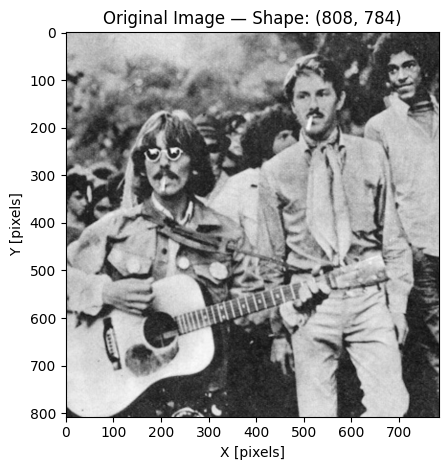

Shape: 808 × 784 pixels
Pixel spacing: dy = 1 pixel, dx = 1 pixel
Sampling frequency: Fy = 1.000, Fx = 1.000 samples/pixel
Nyquist frequency: FNy = 0.500, FNx = 0.500 cycles/pixel
Frequency range: [-0.500, 0.500] cycles/pixel (X), [-0.500, 0.500] cycles/pixel (Y)


In [3]:
# 1. Load image 
image=Image_Data('data/img_try.png')
plt.imshow(image.data, cmap='gray')
plt.title(f'Original Image — Shape: {image.data.shape}')
plt.xlabel('X [pixels]')
plt.ylabel('Y [pixels]')
plt.tight_layout()
plt.show()


# 2. Essential information about the image
print(f"Shape: {image.height} × {image.width} pixels\n"
    f"Pixel spacing: dy = {image.height_spacing} pixel, dx = {image.width_spacing} pixel\n"
    f"Sampling frequency: Fy = {image.height_freq:.3f}, Fx = {image.width_freq:.3f} samples/pixel\n"
    f"Nyquist frequency: FNy = {image.nyquist_height:.3f}, FNx = {image.nyquist_width:.3f} cycles/pixel\n"
    f"Frequency range: "f"[-{image.nyquist_width:.3f}, {image.nyquist_width:.3f}] cycles/pixel (X), "
    f"[-{image.nyquist_height:.3f}, {image.nyquist_height:.3f}] cycles/pixel (Y)"
)

## Insights

> The original image has a spatial resolution of:
>
> $$
> \text{Image shape} = 808 \times 784  = H \times W = N \times M
> $$
>
> where $H$ and $W$ correspond to the number of pixels along the vertical and horizontal dimensions, respectively.
>
> Since the image is sampled every pixel:
>
> $$
> \Delta x = \Delta y = 1 \text{ pixel}
> $$
>
> the spatial sampling frequencies along both axes are:
>
> $$
> F_{s,x}=F_{s,y}=1 \text{ sample/pixel}
> $$
>
> According to the Nyquist criterion, the maximum spatial frequency that can be represented without aliasing is:
>
> $$
> F_N=\frac{F_s}{2}=0.5 \text{ cycles/pixel}
> $$
>
> Therefore, the spatial frequency domain of the original image extends from:
>
> $$
> -0.5 \leq f_x,f_y < 0.5
> \qquad \text{cycles/pixel}
> $$
>
> This means that the highest spatial frequency that can be represented corresponds to an intensity variation occurring every two pixels.

# 2. Exercise Development

> In this exercise, we will study and compare the behavior of the following image filters:
>
> - **Scharr gradient filter** $\rightarrow$ cv2.Scharr()
> - **Sobel filter** $\rightarrow$ cv2.Sobel()
> - **Averaging filter** $\rightarrow$ cv2.blur()
> - **Gaussian filter** $\rightarrow$ cv2.GaussianBlur()
>
> For each filter, we will first perform a **spectral analysis of its impulse response**. By examining the filter in the frequency domain, we can understand which spatial frequencies are attenuated, preserved, or emphasized, and therefore predict its expected effect on the image.
>
> After this theoretical analysis, the filters will be applied to the original image while varying their main parameters. The resulting images will then be compared in both the **spatial domain** and the **frequency domain**.
>
> This approach allows us to directly relate the spectral characteristics of each filter to its visual effect on the image, making it possible to understand why gradient filters enhance edges while smoothing filters reduce high-frequency components and image details.

## 2.1 Scharr gradient filter
The Scharr filter uses two $3\times3$ kernels to estimate the image gradient in the horizontal and vertical directions:

$$
G_x=
\begin{bmatrix}
-3 & 0 & 3\\
-10 & 0 & 10\\
-3 & 0 & 3
\end{bmatrix},
\qquad
G_y=
\begin{bmatrix}
-3 & -10 & -3\\
0 & 0 & 0\\
3 & 10 & 3
\end{bmatrix}
$$

By convolving these kernels with the input image $I$:

$$
I_x = I * G_x,
\qquad
I_y = I * G_y
$$

we obtain approximations of the spatial derivatives:

$$
I_x \approx \frac{\partial I}{\partial x},
\qquad
I_y \approx \frac{\partial I}{\partial y}
$$

Finally, the gradient magnitude can be computed as:

$$
|\nabla I| = \sqrt{I_x^2 + I_y^2}
$$

### 2.1.1 Spectral Analysis

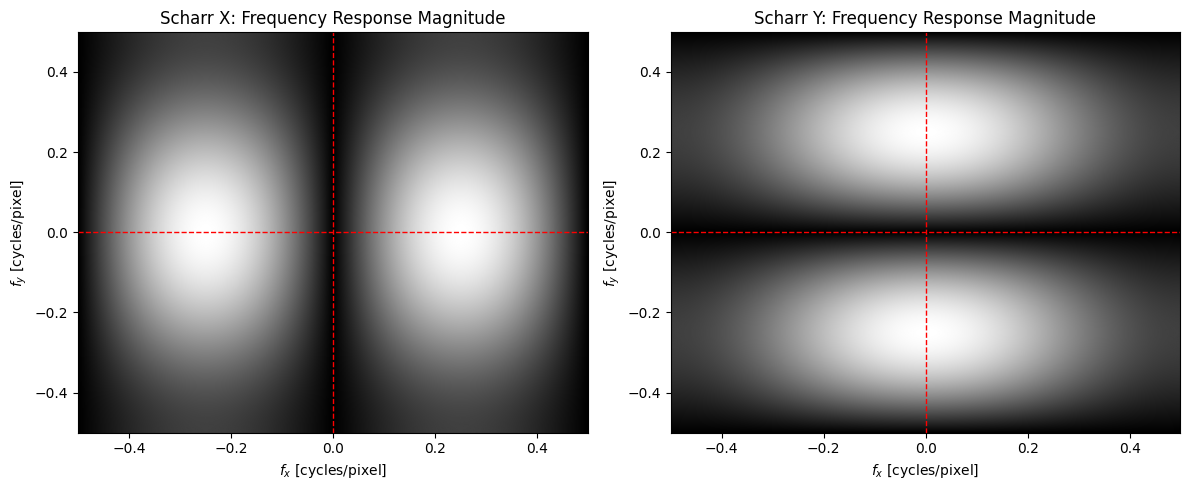

In [4]:
scharr_x=np.array([
    [-3,0,3],
    [-10,0,10],
    [-3,0,3]], dtype=float)

scharr_y=np.array([
    [-3,-10,-3],
    [0,0,0],
    [3,10,3]], dtype=float)

H_x=np.fft.fftshift(np.fft.fft2(scharr_x,s=(image.height,image.width)))
H_y=np.fft.fftshift(np.fft.fft2(scharr_y,s=(image.height,image.width)))

fx=np.fft.fftshift(np.fft.fftfreq(image.width,d=1))
fy=np.fft.fftshift(np.fft.fftfreq(image.height,d=1))

H_x_mag=np.abs(H_x)
H_y_mag=np.abs(H_y)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(
    H_x_mag,
    cmap='gray',
    extent=[fx[0],fx[-1],fy[0],fy[-1]],
    origin='lower',
    aspect='auto'
)
plt.axvline(0,color='red',linestyle='--',linewidth=1)
plt.axhline(0,color='red',linestyle='--',linewidth=1)
plt.title('Scharr X: Frequency Response Magnitude')
plt.xlabel(r'$f_x$ [cycles/pixel]')
plt.ylabel(r'$f_y$ [cycles/pixel]')

plt.subplot(1,2,2)
plt.imshow(
    H_y_mag,
    cmap='gray',
    extent=[fx[0],fx[-1],fy[0],fy[-1]],
    origin='lower',
    aspect='auto'
)
plt.axvline(0,color='red',linestyle='--',linewidth=1)
plt.axhline(0,color='red',linestyle='--',linewidth=1)
plt.title('Scharr Y: Frequency Response Magnitude')
plt.xlabel(r'$f_x$ [cycles/pixel]')
plt.ylabel(r'$f_y$ [cycles/pixel]')

plt.tight_layout()
plt.show()

#### Insight

> The spectral analysis of the Scharr filter was a bit less intuitive than expected. Since Scharr is used for edge detection and behaves like a **high-pass filter**, we might expect a response with a dark region around the center and brighter values towards the highest frequencies.
>
> However, the frequency response shows a different behaviour. Scharr is not an ideal high-pass filter, but a **directional derivative filter**. This is why two kernels are used: **Scharr X** detects changes along the $x$-direction, while **Scharr Y** detects changes along the $y$-direction.
>
> In both cases, very low frequencies are strongly attenuated, which makes sense because constant or slowly varying regions do not produce a strong derivative response. The strongest response appears at **intermediate-to-high frequencies**, corresponding to relatively fast intensity changes such as edges.
>
> What is interesting is that the response decreases again close to the Nyquist frequency, around:
>
> $$
> |f| = 0.5 \ \text{cycles/pixel}
> $$
>
> so the highest possible frequencies are also attenuated.
>
> Therefore, Scharr does not behave like an ideal high-pass filter, which would preserve all frequencies above a certain cutoff frequency. Instead, it mainly enhances **intermediate-to-high frequency variations in a specific direction**, which explains the characteristic lobes observed in the frequency response.

### 2.1.2 Application to the Image

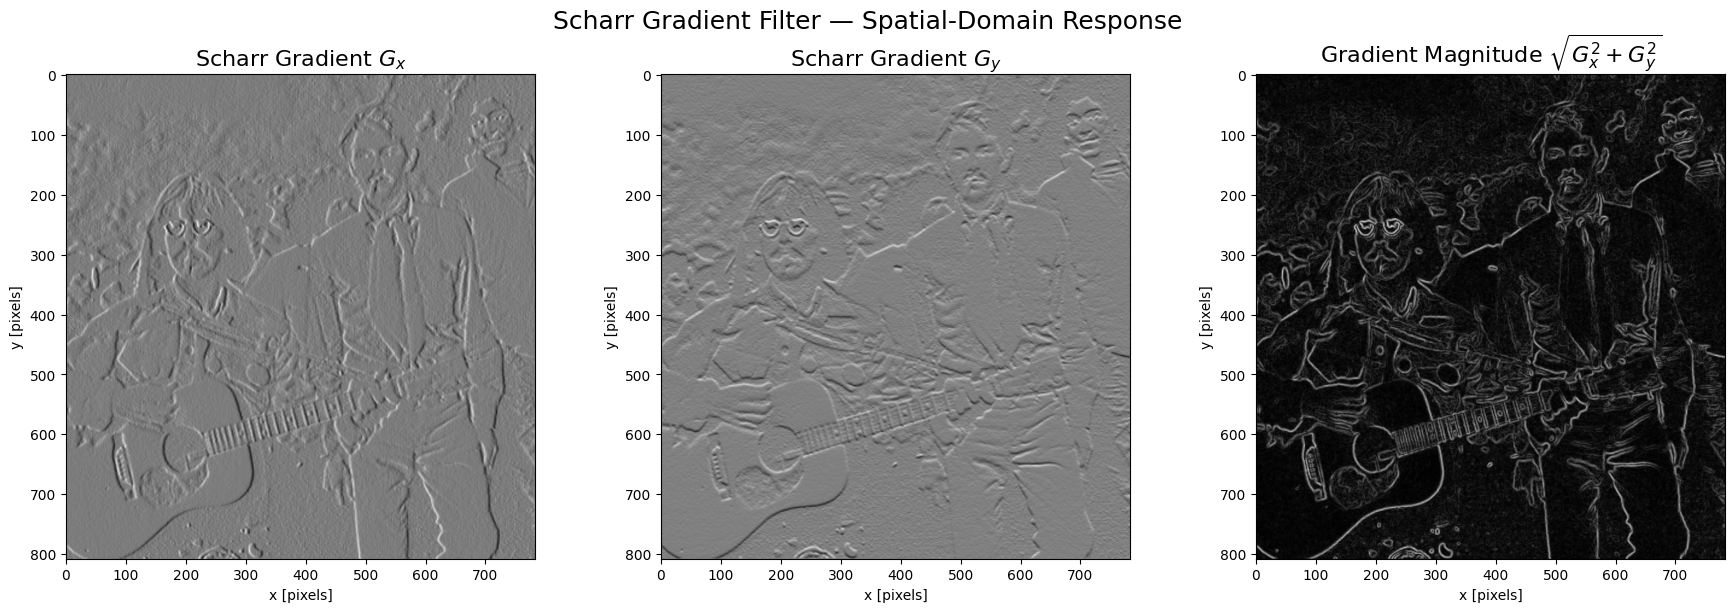

In [5]:
# Apply Scharr gradient filter
grad_x = cv2.Scharr(image.data, cv2.CV_64F, 1, 0)
grad_y = cv2.Scharr(image.data, cv2.CV_64F, 0, 1)

gradient_magnitude = np.sqrt(grad_x**2 + grad_y**2)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(grad_x, cmap='gray')
axes[0].set_title('Scharr Gradient $G_x$', fontsize=16)
axes[0].set_xlabel('x [pixels]')
axes[0].set_ylabel('y [pixels]')

axes[1].imshow(grad_y, cmap='gray')
axes[1].set_title('Scharr Gradient $G_y$', fontsize=16)
axes[1].set_xlabel('x [pixels]')
axes[1].set_ylabel('y [pixels]')

axes[2].imshow(gradient_magnitude, cmap='gray')
axes[2].set_title('Gradient Magnitude $\sqrt{G_x^2 + G_y^2}$', fontsize=16)
axes[2].set_xlabel('x [pixels]')
axes[2].set_ylabel('y [pixels]')

fig.suptitle('Scharr Gradient Filter — Spatial-Domain Response', fontsize=18)
plt.tight_layout()
plt.show()

#### Insight

> The obtained result is the expected one. **Scharr X** detects intensity changes along the $x$-direction, while **Scharr Y** detects changes along the $y$-direction.
>
> This means that Scharr X mainly highlights **vertical edges**, whereas Scharr Y mainly highlights **horizontal edges**.
>
> Finally, both responses are combined using the gradient magnitude:
>
> $$
> |\nabla I| = \sqrt{G_x^2 + G_y^2}
> $$
>
> This gives a single image showing the overall strength of the edges, regardless of their direction. Flat regions remain dark, while strong edges appear brighter.
>
> Unlike other filters studied in this exercise, Scharr uses a **fixed $3\times3$ kernel** with predefined coefficients. Therefore, there are no parameters such as kernel size or $\sigma$ to vary, so only one fixed configuration is analyzed.

## 2.2 Sobel gradient filter

The Sobel filter estimates the horizontal and vertical derivatives of an image. Unlike the Scharr operator, the Sobel operator can be applied using different kernel sizes.

For a kernel size of $3\times3$, the Sobel kernels are:

$$
G_x^{(3)}=
\begin{bmatrix}
-1 & 0 & 1\\
-2 & 0 & 2\\
-1 & 0 & 1
\end{bmatrix},
\qquad
G_y^{(3)}=
\begin{bmatrix}
-1 & -2 & -1\\
0 & 0 & 0\\
1 & 2 & 1
\end{bmatrix}
$$

For larger kernel sizes, such as $5\times5$ or $7\times7$, the same principle is applied using wider derivative and smoothing kernels. Increasing the kernel size makes the derivative estimation depend on a larger neighborhood of pixels.

For each kernel size $k$, the horizontal and vertical derivatives are obtained as:

$$
I_x^{(k)} = I * G_x^{(k)},
\qquad
I_y^{(k)} = I * G_y^{(k)}
$$

which approximate:

$$
I_x^{(k)} \approx \frac{\partial I}{\partial x},
\qquad
I_y^{(k)} \approx \frac{\partial I}{\partial y}
$$

The gradient magnitude is then computed as:

$$
|\nabla I|^{(k)}
=
\sqrt{
\left(I_x^{(k)}\right)^2+
\left(I_y^{(k)}\right)^2
}
$$

Therefore, different kernel sizes such as $3\times3$, $5\times5$, and $7\times7$ can be compared to study how the size of the neighborhood affects the detected image gradients. Smaller kernels preserve more local details, while larger kernels introduce more smoothing and produce a gradient estimation based on a wider spatial neighborhood.

### 2.2.1 Spectral Analysis

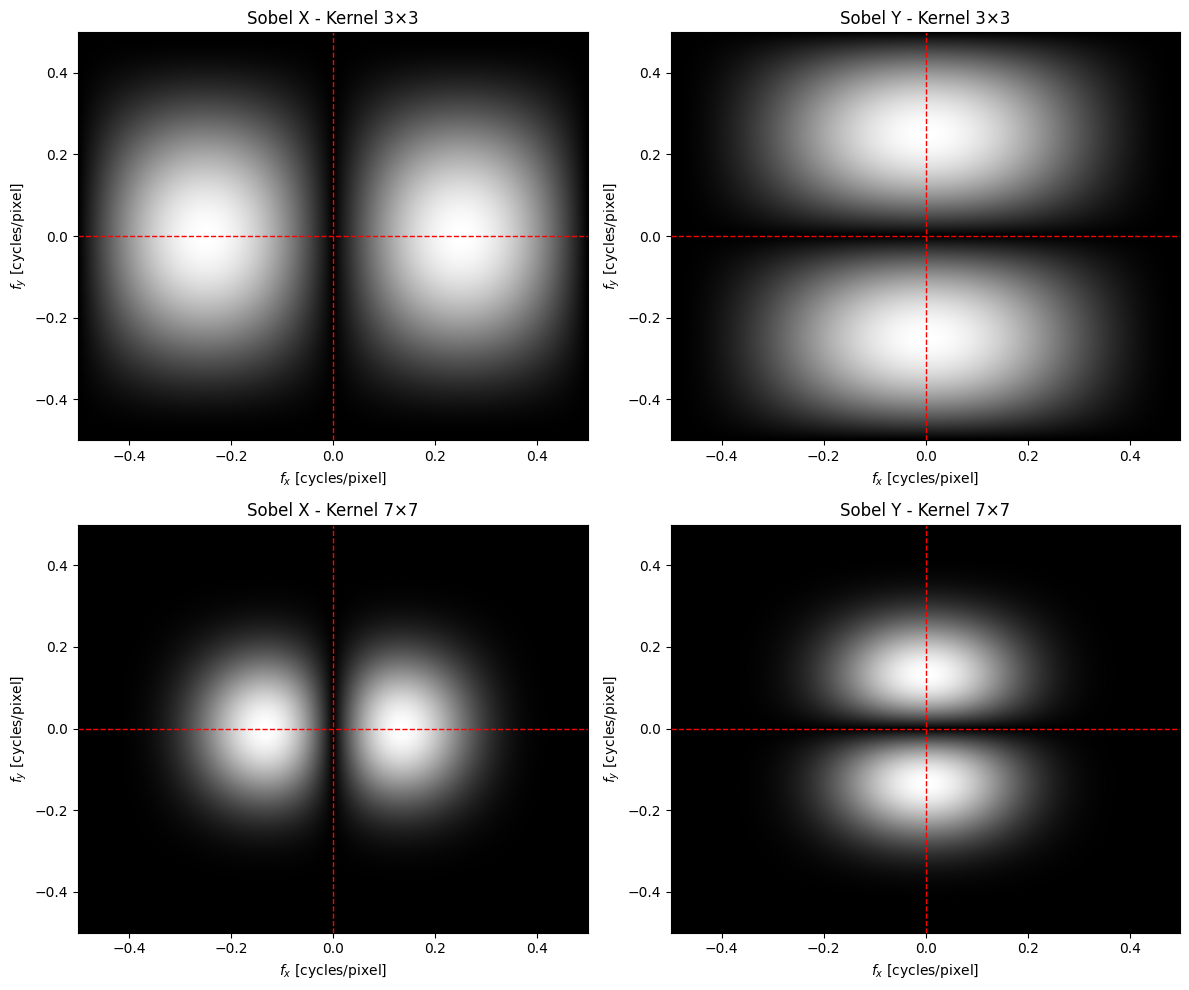

In [6]:
# Sobel 3x3
sobel_x_3 = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]], dtype=float)

sobel_y_3 = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]], dtype=float)


# Sobel 7x7
sobel_x_7 = np.array([
    [ -1,  -4,   -5,   0,    5,   4,  1],
    [ -6, -24,  -30,   0,   30,  24,  6],
    [-15, -60,  -75,   0,   75,  60, 15],
    [-20, -80, -100,   0,  100,  80, 20],
    [-15, -60,  -75,   0,   75,  60, 15],
    [ -6, -24,  -30,   0,   30,  24,  6],
    [ -1,  -4,   -5,   0,    5,   4,  1]], dtype=float)

sobel_y_7 = np.array([
    [ -1,  -6,  -15,  -20,  -15,  -6, -1],
    [ -4, -24,  -60,  -80,  -60, -24, -4],
    [ -5, -30,  -75, -100,  -75, -30, -5],
    [  0,   0,    0,    0,    0,   0,  0],
    [  5,  30,   75,  100,   75,  30,  5],
    [  4,  24,   60,   80,   60,  24,  4],
    [  1,   6,   15,   20,   15,   6,  1]], dtype=float)


H_x_3 = np.fft.fftshift(np.fft.fft2(sobel_x_3, s=(image.height, image.width)))
H_y_3 = np.fft.fftshift(np.fft.fft2(sobel_y_3, s=(image.height, image.width)))

H_x_7 = np.fft.fftshift(np.fft.fft2(sobel_x_7, s=(image.height, image.width)))
H_y_7 = np.fft.fftshift(np.fft.fft2(sobel_y_7, s=(image.height, image.width)))

# Frequency axes
fx = np.fft.fftshift(np.fft.fftfreq(image.width, d=1))
fy = np.fft.fftshift(np.fft.fftfreq(image.height, d=1))

# Magnitudes
H_x_3_mag = np.abs(H_x_3)
H_y_3_mag = np.abs(H_y_3)

H_x_7_mag = np.abs(H_x_7)
H_y_7_mag = np.abs(H_y_7)


plt.figure(figsize=(12, 10))
# Sobel X - 3x3
plt.subplot(2, 2, 1)
plt.imshow(
    H_x_3_mag,
    cmap='gray',
    extent=[fx[0], fx[-1], fy[0], fy[-1]],
    origin='lower',
    aspect='auto'
)
plt.axvline(0, color='red', linestyle='--', linewidth=1)
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('Sobel X - Kernel 3×3')
plt.xlabel(r'$f_x$ [cycles/pixel]')
plt.ylabel(r'$f_y$ [cycles/pixel]')

# Sobel Y - 3x3
plt.subplot(2, 2, 2)
plt.imshow(
    H_y_3_mag,
    cmap='gray',
    extent=[fx[0], fx[-1], fy[0], fy[-1]],
    origin='lower',
    aspect='auto'
)
plt.axvline(0, color='red', linestyle='--', linewidth=1)
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('Sobel Y - Kernel 3×3')
plt.xlabel(r'$f_x$ [cycles/pixel]')
plt.ylabel(r'$f_y$ [cycles/pixel]')

# Sobel X - 7x7
plt.subplot(2, 2, 3)
plt.imshow(
    H_x_7_mag,
    cmap='gray',
    extent=[fx[0], fx[-1], fy[0], fy[-1]],
    origin='lower',
    aspect='auto'
)
plt.axvline(0, color='red', linestyle='--', linewidth=1)
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('Sobel X - Kernel 7×7')
plt.xlabel(r'$f_x$ [cycles/pixel]')
plt.ylabel(r'$f_y$ [cycles/pixel]')

# Sobel Y - 7x7
plt.subplot(2, 2, 4)
plt.imshow(
    H_y_7_mag,
    cmap='gray',
    extent=[fx[0], fx[-1], fy[0], fy[-1]],
    origin='lower',
    aspect='auto'
)
plt.axvline(0, color='red', linestyle='--', linewidth=1)
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('Sobel Y - Kernel 7×7')
plt.xlabel(r'$f_x$ [cycles/pixel]')
plt.ylabel(r'$f_y$ [cycles/pixel]')


plt.tight_layout()
plt.show()

#### Insight

> Unlike the Scharr filter, which uses a fixed kernel, the Sobel operator can be applied with different kernel sizes. This allows us to study how the number of neighboring pixels affects the detected gradients.
>
> With a small kernel, such as **3×3**, the operation is more local. The filter is therefore more sensitive to small intensity variations, fine details, and also high-frequency noise.
>
> When the kernel size increases to **7×7**, more neighboring pixels are considered. The gradient is then estimated over a larger spatial region, producing a smoother and less local response.
>
> This behavior is also observed in the frequency domain. For the **3×3 kernel**, the frequency response is more spread out, meaning that a wider range of frequencies contributes to the output. In contrast, for the **7×7 kernel**, the response becomes more concentrated around lower and intermediate frequencies, while the highest frequencies are more strongly attenuated.
>
> Therefore, increasing the Sobel kernel size introduces a stronger smoothing effect:
>
> $$
> \text{larger kernel}
> \quad\Longrightarrow\quad
> \text{more neighbors}
> \quad\Longrightarrow\quad
> \text{more smoothing}
> \quad\Longrightarrow\quad
> \text{larger-scale edges}
> $$
>
> In both cases, Sobel X and Sobel Y remain directional filters: **Sobel X** detects intensity variations along the horizontal direction, while **Sobel Y** detects variations along the vertical direction.

### 2.2.2 Application to the Image

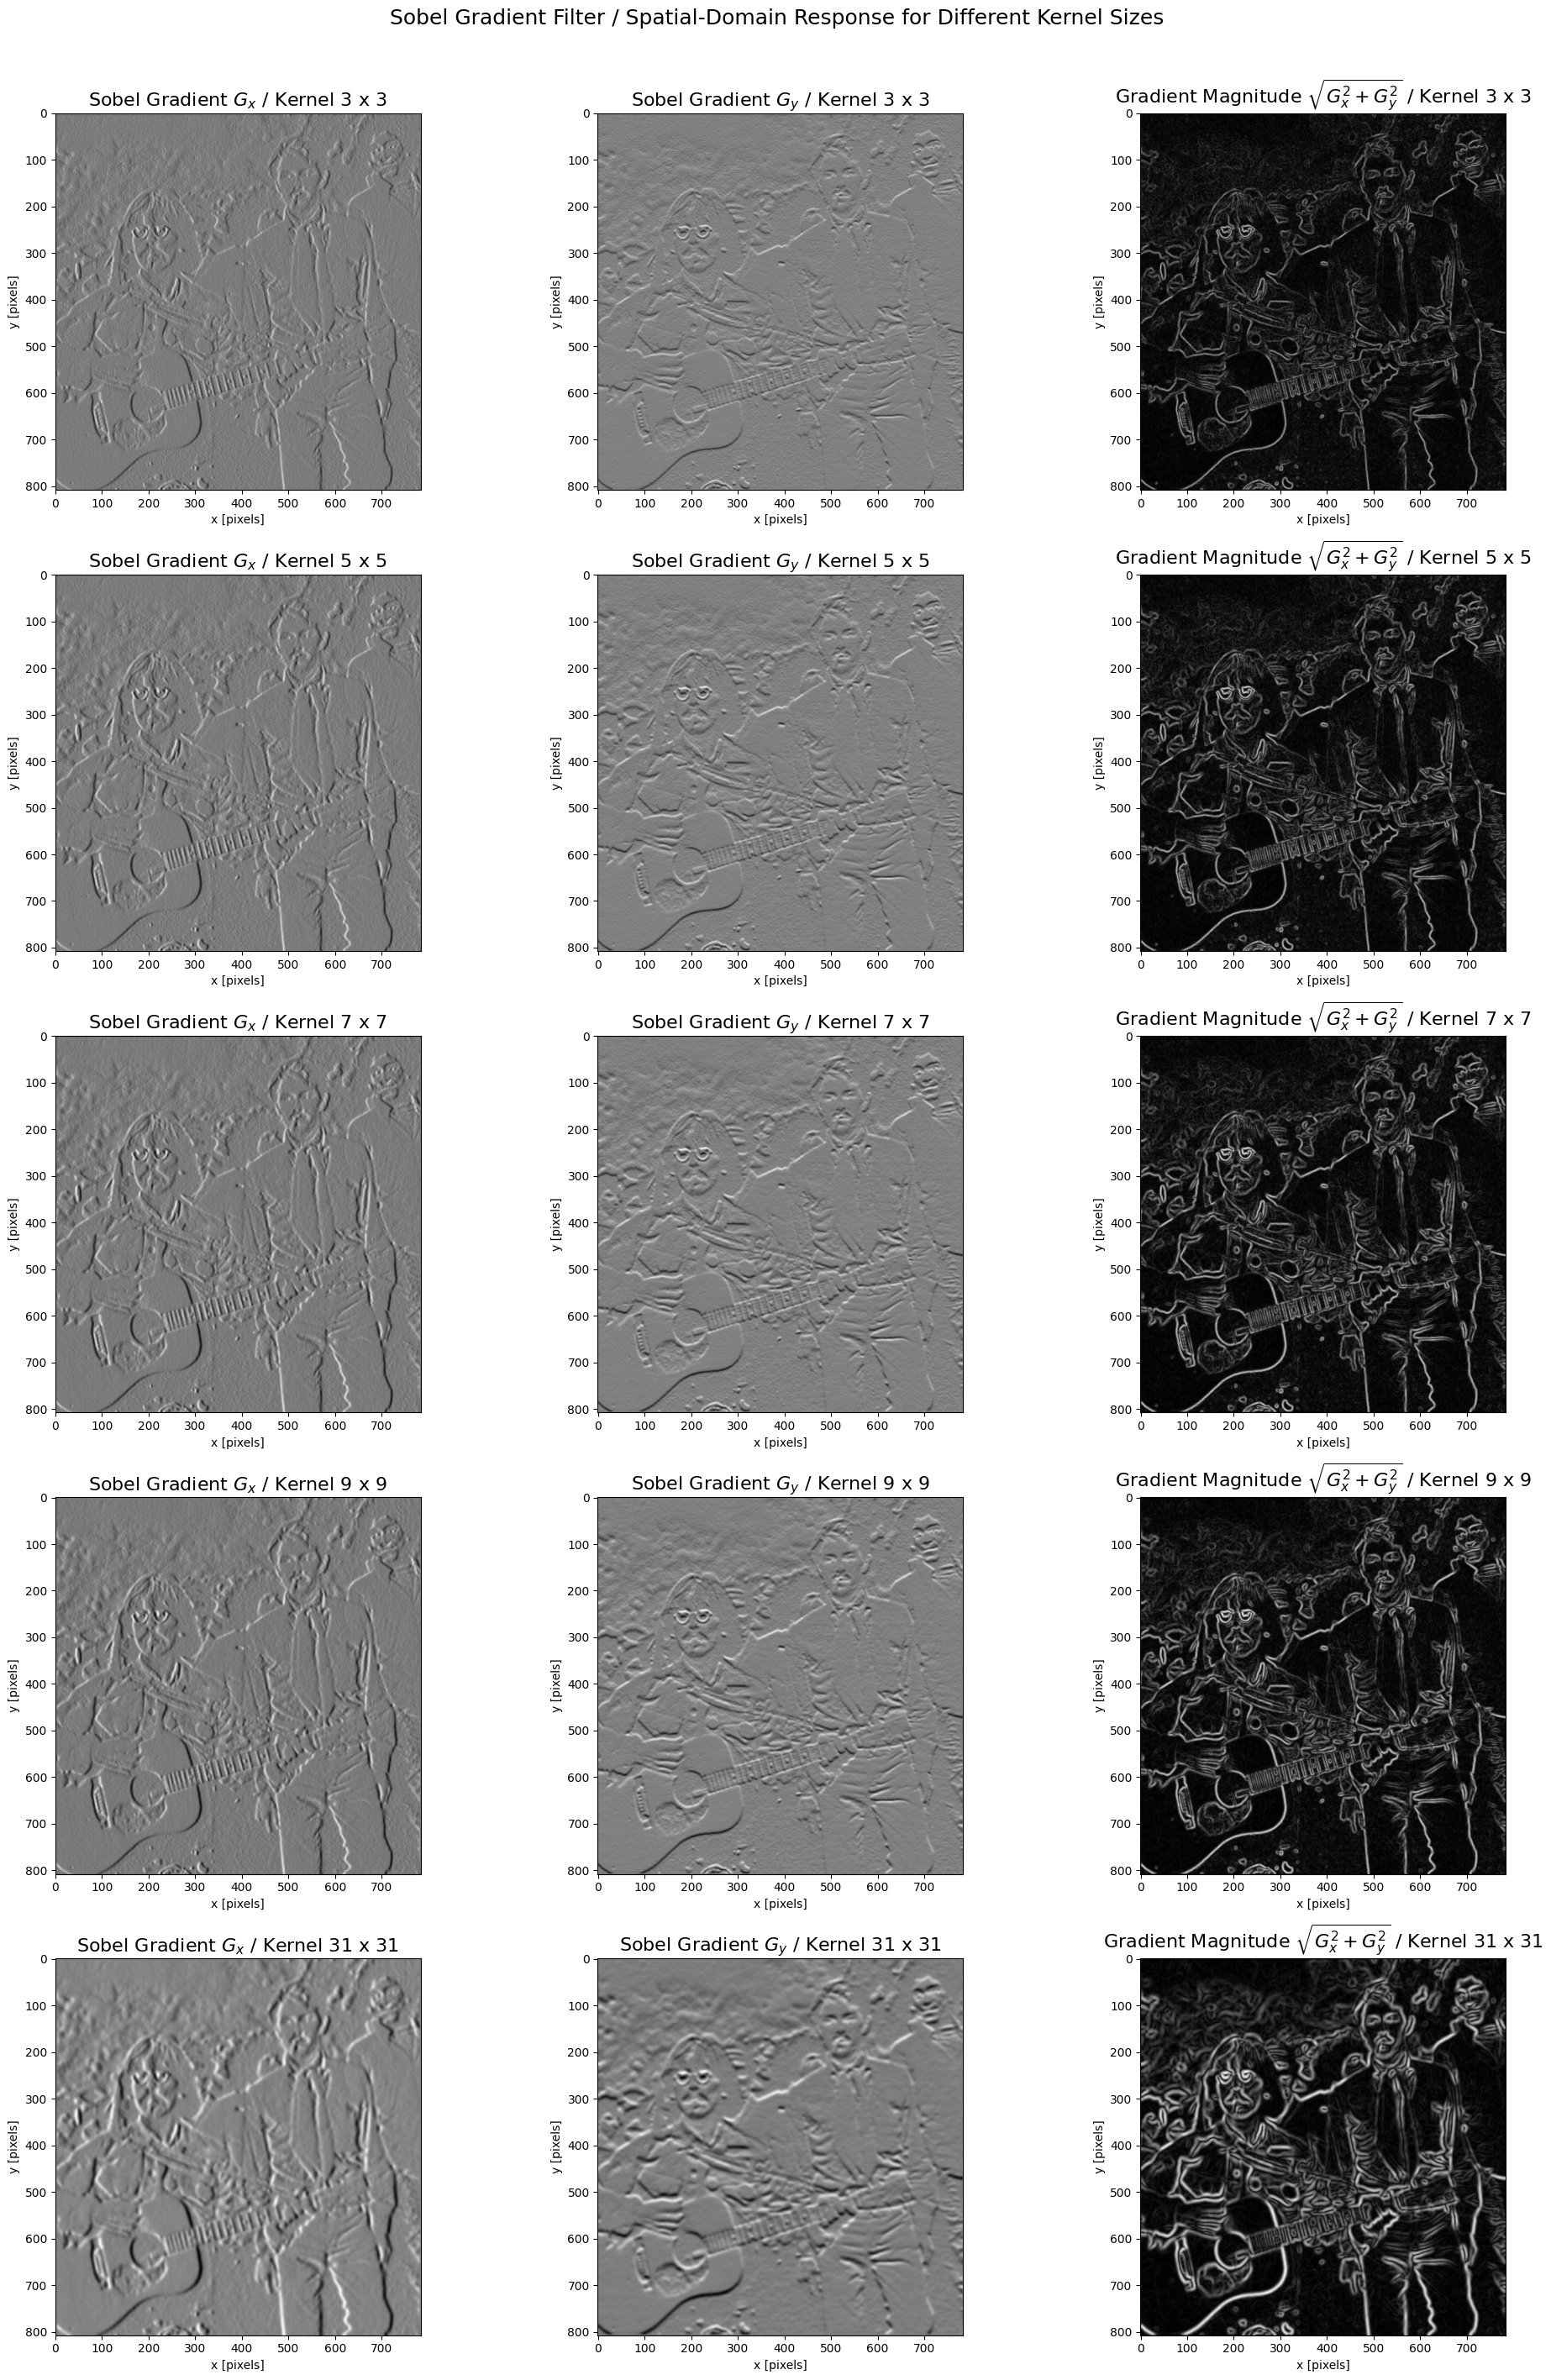

In [7]:
kernel_sizes = [3, 5, 7, 9, 31]

fig, axes = plt.subplots(len(kernel_sizes), 3,figsize=(20, 28))

for i, kernel in enumerate(kernel_sizes):
    sobel_x = cv2.Sobel(image.data, cv2.CV_64F, 1, 0, ksize=kernel)
    sobel_y = cv2.Sobel(image.data, cv2.CV_64F, 0, 1, ksize=kernel)

    gradient_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

    axes[i, 0].imshow(sobel_x, cmap='gray')
    axes[i, 0].set_title(f'Sobel Gradient $G_x$ / Kernel {kernel} x {kernel}', fontsize=16)
    axes[i, 0].set_xlabel('x [pixels]')
    axes[i, 0].set_ylabel('y [pixels]')

    axes[i, 1].imshow(sobel_y, cmap='gray')
    axes[i, 1].set_title( f'Sobel Gradient $G_y$ / Kernel {kernel} x {kernel}', fontsize=16)
    axes[i, 1].set_xlabel('x [pixels]')
    axes[i, 1].set_ylabel('y [pixels]')

    axes[i, 2].imshow(gradient_magnitude, cmap='gray')
    axes[i, 2].set_title(f'Gradient Magnitude $\sqrt{{G_x^2+G_y^2}}$ / Kernel {kernel} x {kernel}', fontsize=16)
    axes[i, 2].set_xlabel('x [pixels]')
    axes[i, 2].set_ylabel('y [pixels]')

fig.suptitle(
    'Sobel Gradient Filter / Spatial-Domain Response for Different Kernel Sizes',
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

#### Insight

> The images clearly show the effect of increasing the Sobel kernel size.
>
> With a small kernel, such as **3×3**, the detected edges are thinner and more local, because the gradient is computed using only the pixels close to each point.
>
> As the kernel size increases, more neighboring pixels are taken into account. As a result, the response spreads over a larger area and the edges become **wider and smoother**.
>
> This is especially visible for the **31×31 kernel**, where the detected lines become **thicker**, since the gradient response is distributed over more pixels. At the same time, the contours are less local and small details become less pronounced.
>
> Therefore, the results obtained in the images agree with the spectral analysis: larger kernels produce a stronger smoothing effect and emphasize larger-scale structures instead of very fine details.
>
> $$
> \text{larger kernel}
> \rightarrow
> \text{more neighbors}
> \rightarrow
> \text{more smoothing}
> \rightarrow
> \text{thicker, wider and less local edges}
> $$1

## 2.3 Averaging filter

The averaging filter is a smoothing filter that replaces each pixel by the average intensity of the pixels within a local neighborhood. Unlike gradient filters, its objective is not to detect intensity variations but to reduce local variations and smooth the image.

For a kernel size of $3\times3$, the averaging kernel is:

$$
H^{(3)}=
\frac{1}{9}
\begin{bmatrix}
1 & 1 & 1\\
1 & 1 & 1\\
1 & 1 & 1
\end{bmatrix}
$$

More generally, for a kernel of size $k\times k$, the averaging filter is defined as:

$$
H^{(k)}=
\frac{1}{k^2}
\begin{bmatrix}
1 & \cdots & 1\\
\vdots & \ddots & \vdots\\
1 & \cdots & 1
\end{bmatrix}
$$

where all the pixels inside the neighborhood have the same contribution to the output.

By convolving the averaging kernel with the input image $I$:

$$
I_{\mathrm{avg}}^{(k)} = I * H^{(k)}
$$

each output pixel is computed as the mean value of the pixels contained in its $k\times k$ neighborhood:

$$
I_{\mathrm{avg}}^{(k)}(x,y)
=
\frac{1}{k^2}
\sum_{i}
\sum_{j}
I(x+i,y+j)
$$

Therefore, different kernel sizes such as $3\times3$, $5\times5$, and $7\times7$ can be compared to study how the size of the neighborhood affects image smoothing. Smaller kernels produce a moderate smoothing effect and preserve more local details, while larger kernels average a wider spatial neighborhood, producing stronger smoothing but also removing more edges, textures, and high-frequency image information.

### 2.3.1 Spectral Analysis

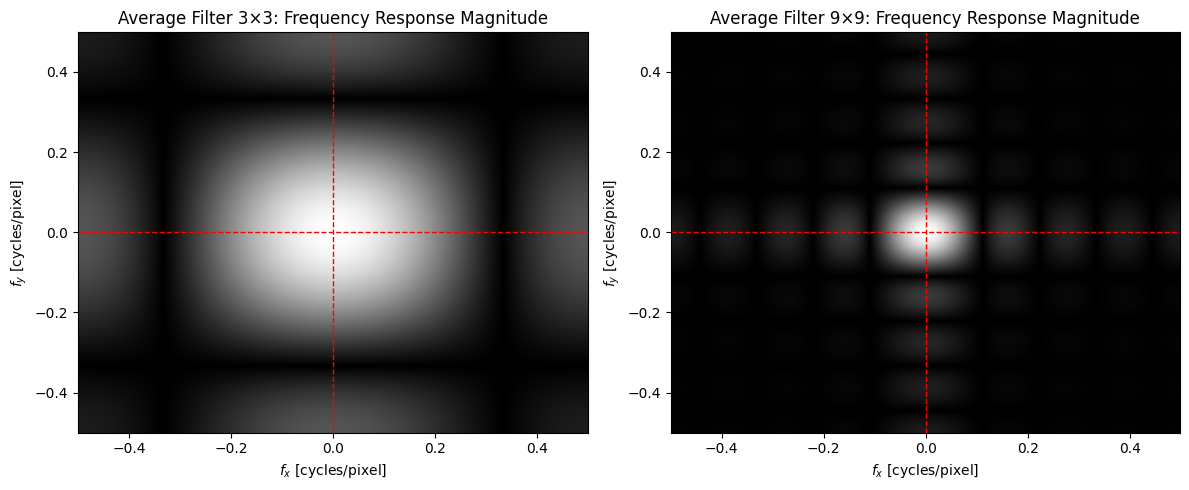

In [8]:
avg_3=np.ones((3,3),dtype=float)/3**2
avg_9=np.ones((9,9),dtype=float)/9**2

H_3=np.fft.fftshift(np.fft.fft2(avg_3,s=(image.height,image.width)))
H_9=np.fft.fftshift(np.fft.fft2(avg_9,s=(image.height,image.width)))

fx=np.fft.fftshift(np.fft.fftfreq(image.width,d=1))
fy=np.fft.fftshift(np.fft.fftfreq(image.height,d=1))

H_3_mag=np.abs(H_3)
H_9_mag=np.abs(H_9)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(
    H_3_mag,
    cmap='gray',
    extent=[fx[0],fx[-1],fy[0],fy[-1]],
    origin='lower',
    aspect='auto'
)
plt.axvline(0,color='red',linestyle='--',linewidth=1)
plt.axhline(0,color='red',linestyle='--',linewidth=1)
plt.title('Average Filter 3×3: Frequency Response Magnitude')
plt.xlabel(r'$f_x$ [cycles/pixel]')
plt.ylabel(r'$f_y$ [cycles/pixel]')

plt.subplot(1,2,2)
plt.imshow(
    H_9_mag,
    cmap='gray',
    extent=[fx[0],fx[-1],fy[0],fy[-1]],
    origin='lower',
    aspect='auto'
)
plt.axvline(0,color='red',linestyle='--',linewidth=1)
plt.axhline(0,color='red',linestyle='--',linewidth=1)
plt.title('Average Filter 9×9: Frequency Response Magnitude')
plt.xlabel(r'$f_x$ [cycles/pixel]')
plt.ylabel(r'$f_y$ [cycles/pixel]')

plt.tight_layout()
plt.show()

#### Insight

> The spectral analysis confirms that the averaging filter behaves as a **low-pass filter**, since its maximum response is concentrated around zero frequency $(f_x,f_y)=(0,0)$, while higher spatial frequencies are progressively attenuated.
>
> Moreover, increasing the kernel size from $3\times3$ to $9\times9$ makes the filter more restrictive in the frequency domain. The central passband becomes narrower, meaning that a smaller range of spatial frequencies is preserved.
>
> Therefore, a larger averaging kernel removes more high-frequency components, such as fine details, textures, and sharp edges, resulting in stronger smoothing of the image.

### 2.3.2 Application to the Image

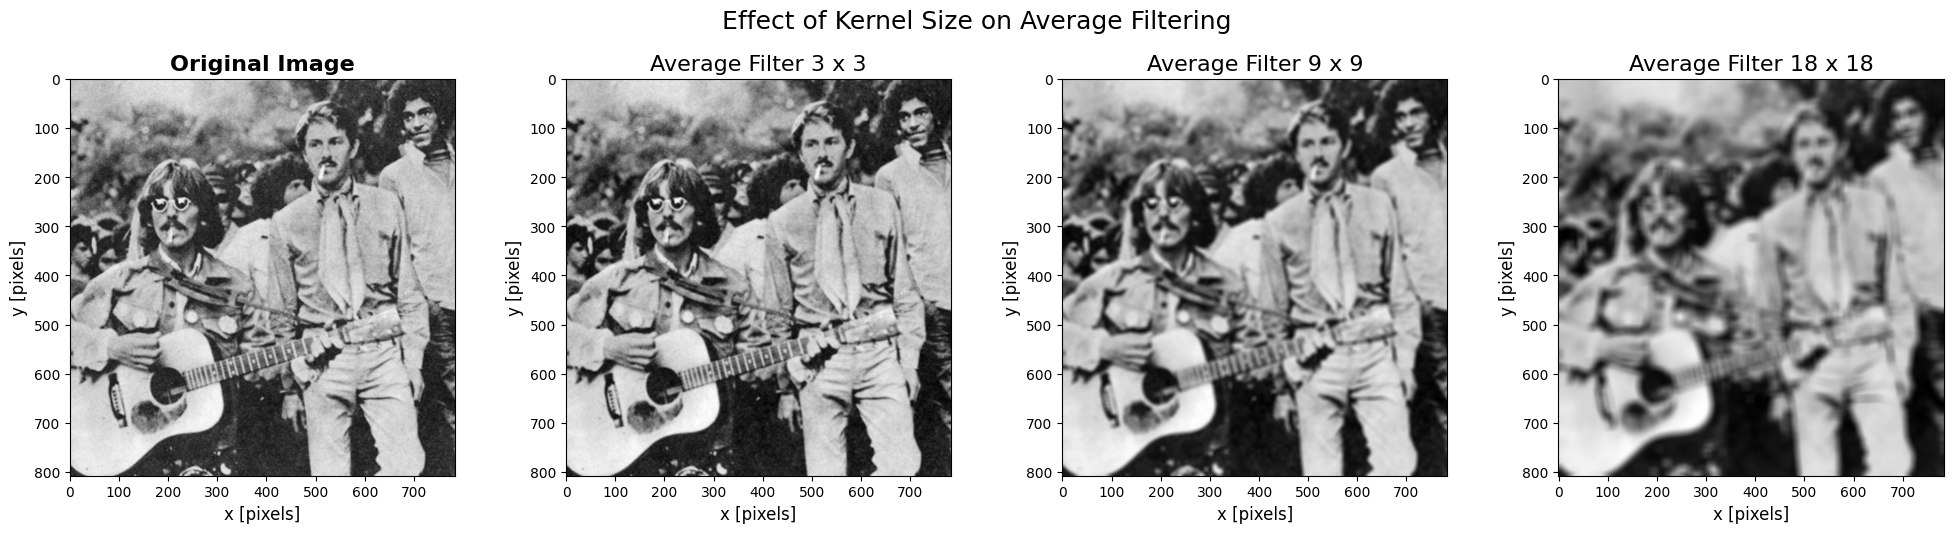

In [9]:
list_of_kernels=[(3,3),(9,9),(18,18)]

fig,axes=plt.subplots(1,4,figsize=(20,5))


axes[0].imshow(image.data,cmap='gray')
axes[0].set_title("Original Image",fontsize=16,fontweight='bold')
axes[0].set_xlabel("x [pixels]",fontsize=12)
axes[0].set_ylabel("y [pixels]",fontsize=12)
axes[0].tick_params(labelsize=10)

for i,kernel in enumerate(list_of_kernels,1):
    average=cv2.blur(image.data,kernel)

    axes[i].imshow(average,cmap='gray')
    axes[i].set_title(
        f"Average Filter {kernel[0]} x {kernel[1]}",
        fontsize=16)
    
    axes[i].set_xlabel("x [pixels]",fontsize=12)
    axes[i].set_ylabel("y [pixels]",fontsize=12)
    axes[i].tick_params(labelsize=10)

fig.suptitle(
    "Effect of Kernel Size on Average Filtering",
    fontsize=18,
    y=1.02)

plt.tight_layout()
plt.show()

#### Insight

> As we can observe, the prediction made from the spectral analysis is confirmed in the spatial domain. As the kernel size increases from $3\times3$ to $9\times9$ and $18\times18$, the averaging filter becomes more restrictive and progressively removes high-frequency components.
>
> Consequently, the image becomes increasingly smoother, preserving mainly the low-frequency information while losing fine details, textures, and sharp edges, which are associated with higher spatial frequencies.

## 2.4 Gaussian filter

The Gaussian filter is a smoothing filter that gives more weight to pixels close to the center of the kernel and less weight to pixels farther away.

<p align="center">
  <img src="gaussian_filter.png" width="450">
</p>

The Gaussian kernel is defined by:

$$
G(x,y)=\frac{1}{2\pi\sigma^2}
\exp\left(
-\frac{x^2+y^2}{2\sigma^2}
\right)
$$

where $\sigma$ controls the spread of the Gaussian distribution.

The filtered image is obtained by convolving the input image $I$ with the Gaussian kernel:

$$
I_G=I*G
$$

A small $\sigma$ produces less smoothing, while a larger $\sigma$ produces stronger smoothing. The kernel size determines the spatial neighborhood used to represent the Gaussian.

### 2.4.1 Spectral Analysis

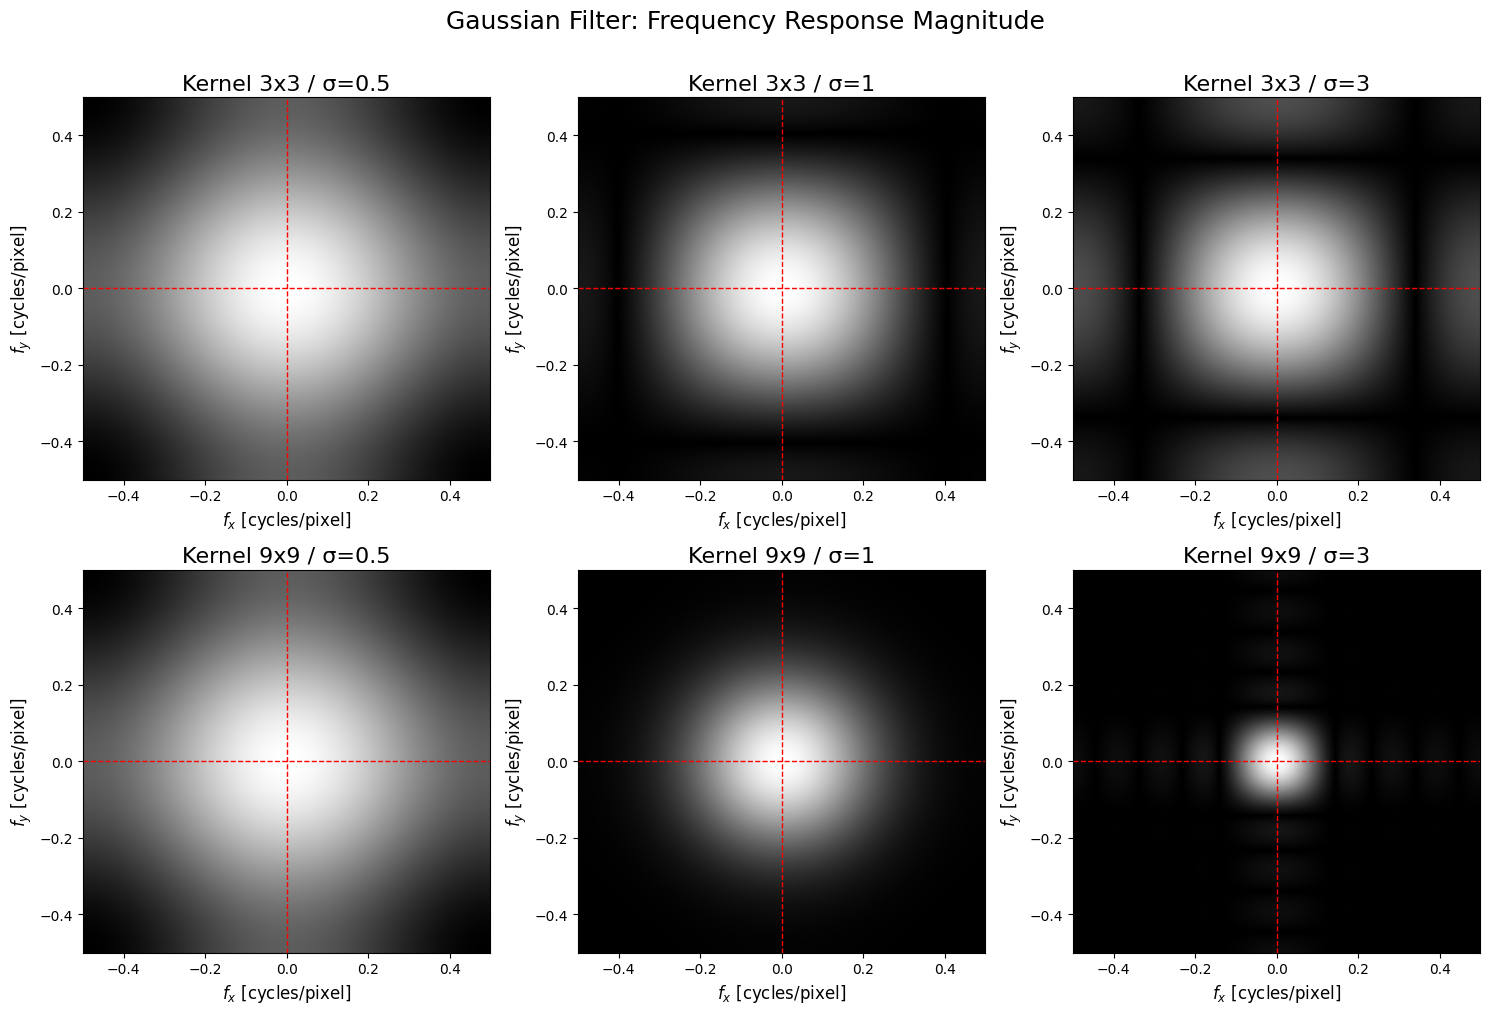

In [10]:
kernel_sizes=[3,9]
sigma_values=[0.5,1,3]

fx=np.fft.fftshift(np.fft.fftfreq(image.width,d=1))
fy=np.fft.fftshift(np.fft.fftfreq(image.height,d=1))

fig,axes=plt.subplots(2,3,figsize=(15,10))

for i,kernel_size in enumerate(kernel_sizes):
    for j,sigma in enumerate(sigma_values):
        gaussian_1d=cv2.getGaussianKernel(kernel_size,sigma)
        gaussian_2d=gaussian_1d@gaussian_1d.T

        H=np.fft.fftshift(np.fft.fft2(gaussian_2d, s=(image.height,image.width)))
        H_mag=np.abs(H)

        axes[i,j].imshow(
            H_mag,
            cmap='gray',
            extent=[fx[0],fx[-1],fy[0],fy[-1]],
            origin='lower',
            aspect='auto'
        )

        axes[i,j].axvline(0,color='red',linestyle='--',linewidth=1)
        axes[i,j].axhline(0,color='red',linestyle='--',linewidth=1)
        axes[i,j].set_title(
            f"Kernel {kernel_size}x{kernel_size} / σ={sigma}",
            fontsize=16
        )
        axes[i,j].set_xlabel(r'$f_x$ [cycles/pixel]',fontsize=12)
        axes[i,j].set_ylabel(r'$f_y$ [cycles/pixel]',fontsize=12)
        axes[i,j].tick_params(labelsize=10)

fig.suptitle(
    "Gaussian Filter: Frequency Response Magnitude",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

## Insights

> The frequency response shows that the Gaussian filter behaves as a **low-pass filter**. The highest response is concentrated around:
>
> $$
> f_x=f_y=0
> $$
>
> This means that low frequencies are preserved, while high frequencies are attenuated. In the image domain, this produces a smoothing effect and reduces noise, fine details, and sharp intensity changes.
>
> The parameter $\sigma$ controls how spread the Gaussian is in the spatial domain. A small $\sigma$ concentrates most of the weight around the central pixel, so the filter produces only a small amount of smoothing.
>
> When $\sigma$ increases, more neighboring pixels contribute to the result and the smoothing effect becomes stronger.
>
> In the frequency domain, the opposite behavior is observed:
>
> $$
> \sigma\uparrow
> \quad\Longrightarrow\quad
> \text{narrower frequency response}
> $$
>
> Therefore, a larger $\sigma$ removes more high-frequency components, while a smaller $\sigma$ allows a wider range of frequencies to pass.
>
> The kernel size determines how many neighboring pixels are available to represent the Gaussian. However, increasing the kernel size does not necessarily produce stronger smoothing if $\sigma$ remains small.
>
> This can be observed in the frequency responses for $\sigma=0.5$: the $3\times3$ and $9\times9$ kernels produce almost the same response because most of the Gaussian weight is still concentrated around the central pixel. The additional pixels of the larger kernel have coefficients close to zero and therefore have very little effect.
>
> For this reason, when using a larger kernel, $\sigma$ should also be large enough to make use of the additional neighboring pixels.
>
> In general:
>
> $$
> \text{larger kernel}+\text{small }\sigma
> \approx
> \text{smaller kernel}+\text{small }\sigma
> $$
>
> while increasing $\sigma$ produces a stronger low-pass effect and greater attenuation of high frequencies.

### 2.4.2 Application to the Image

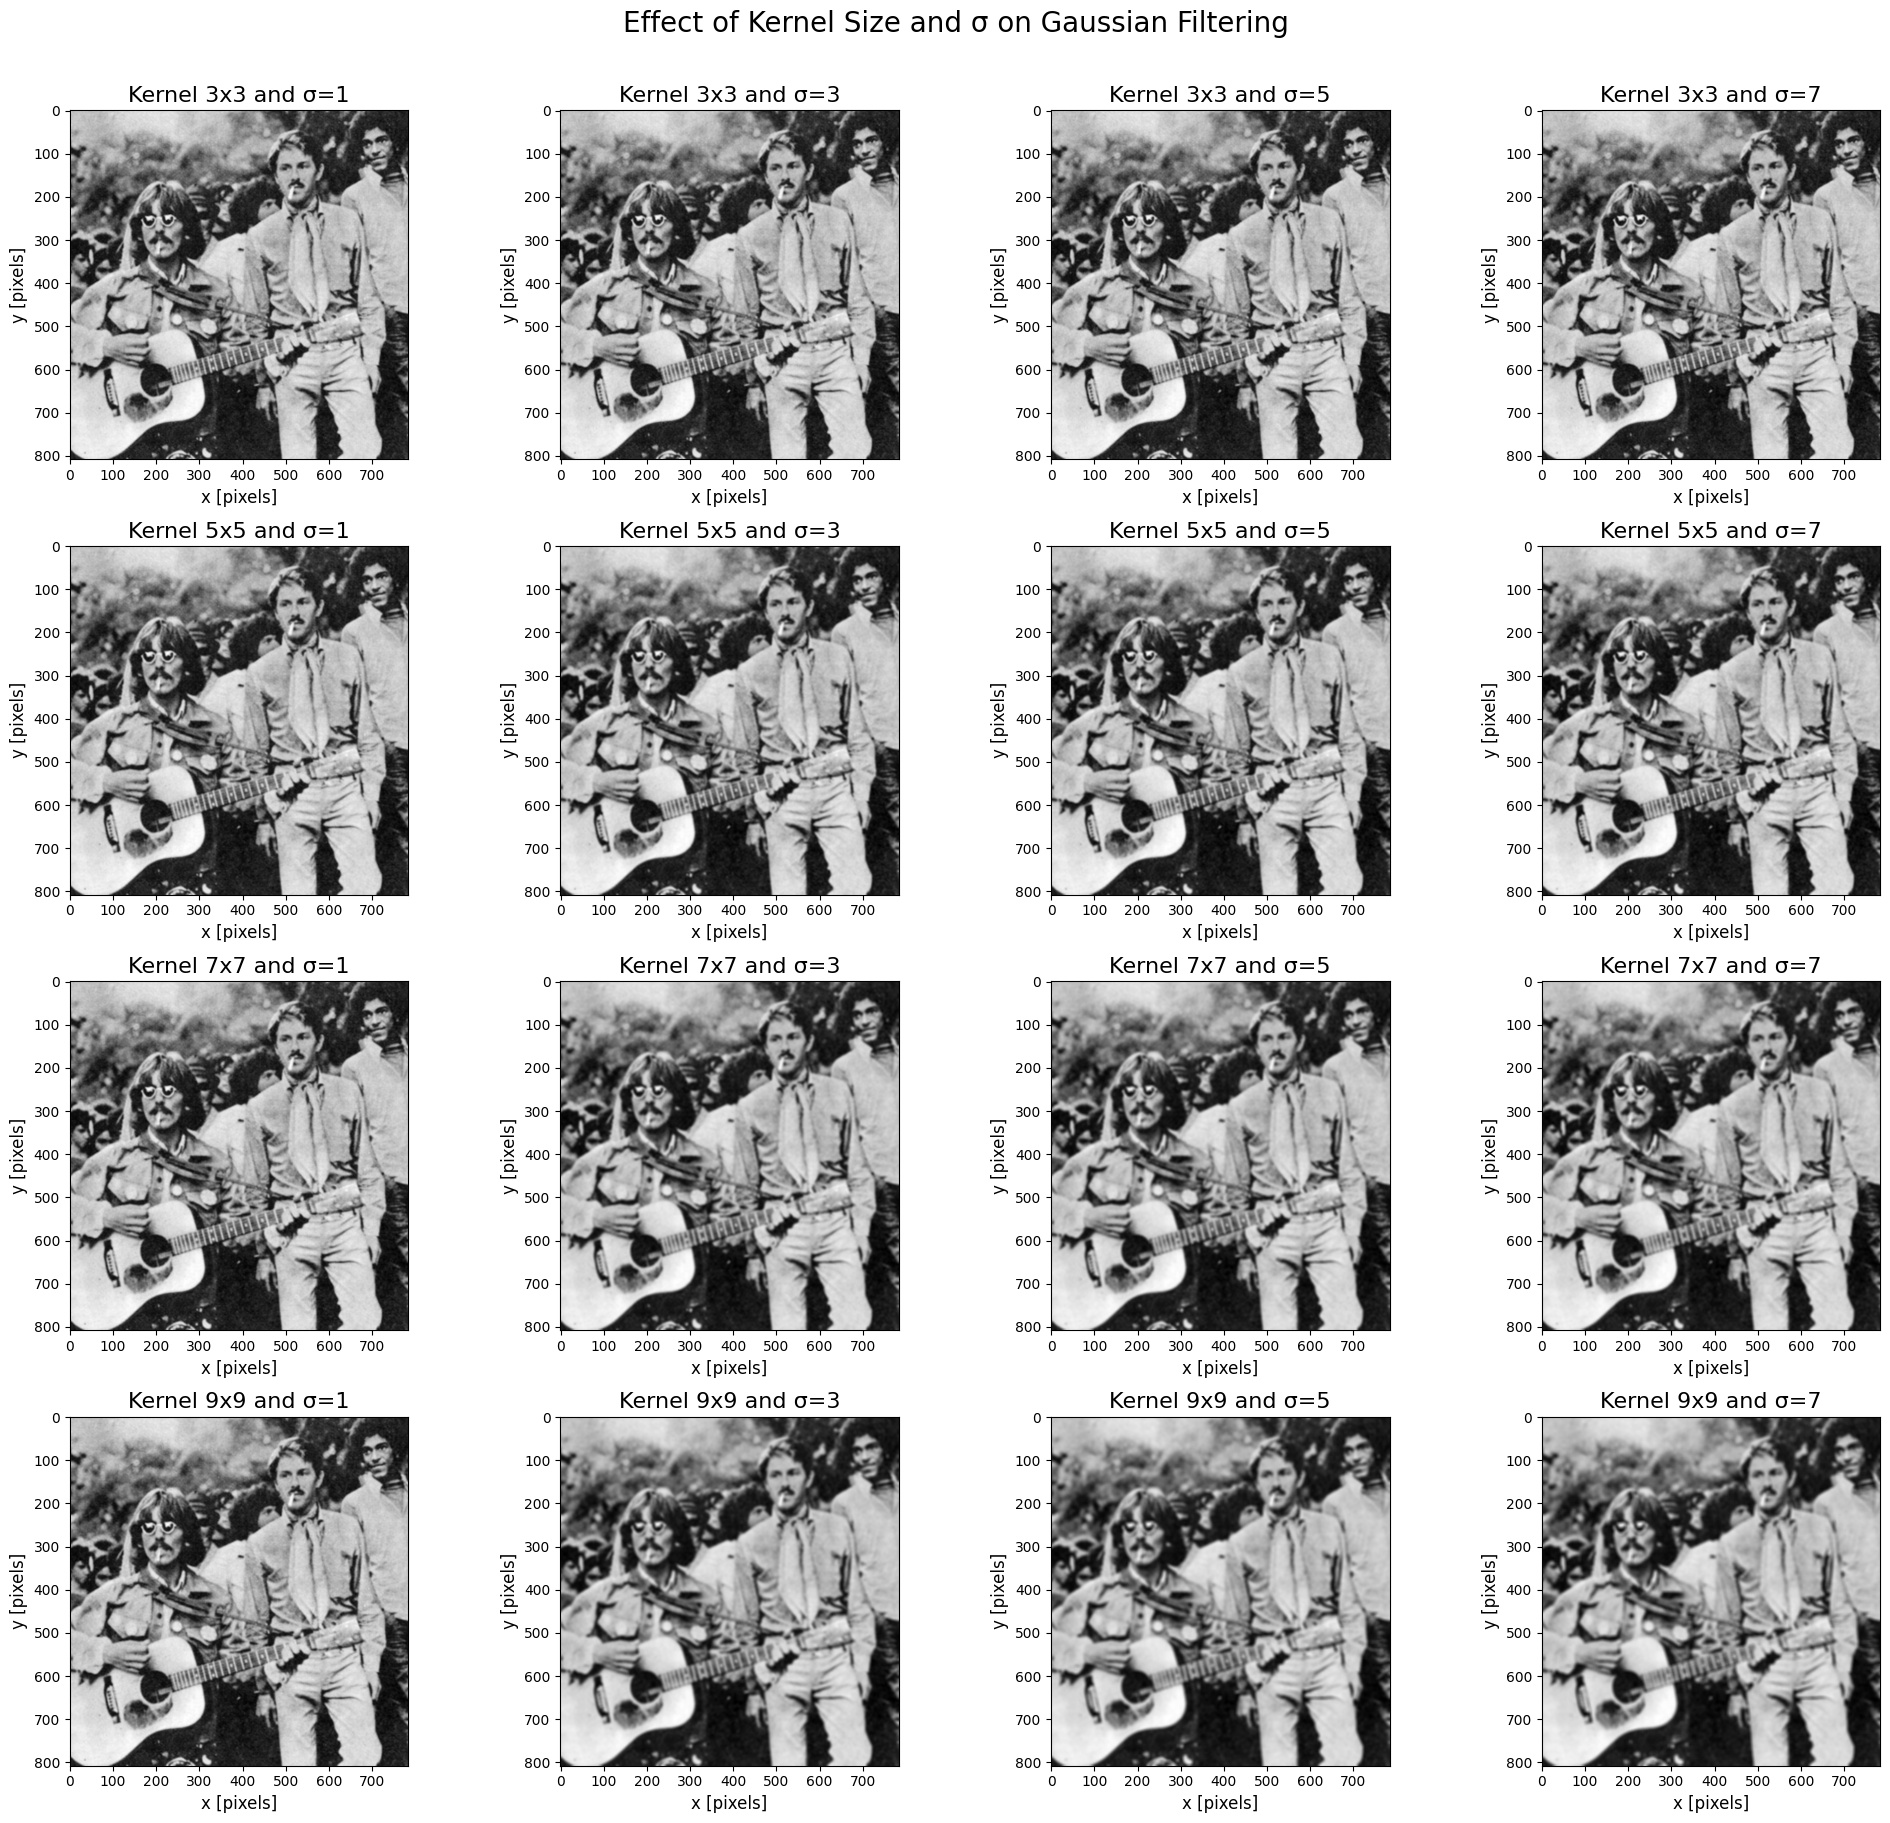

In [11]:
sigma_values=[1,3,5,7]
list_of_kernels=[(3,3),(5,5),(7,7),(9,9)]

fig,axes=plt.subplots(4,4,figsize=(20,18))

for i,kernel in enumerate(list_of_kernels):
    for j,sigma in enumerate(sigma_values):
        gaussian=cv2.GaussianBlur(image.data,kernel,sigma)

        axes[i,j].imshow( gaussian, cmap='gray')

        axes[i,j].set_title(
            f"Kernel {kernel[0]}x{kernel[1]} and σ={sigma}",
            fontsize=16)

        axes[i,j].set_xlabel("x [pixels]",fontsize=12)
        axes[i,j].set_ylabel("y [pixels]",fontsize=12)
        axes[i,j].tick_params(labelsize=10)

fig.suptitle(
    "Effect of Kernel Size and σ on Gaussian Filtering",
    fontsize=20,
    y=1.01
)

plt.tight_layout()
plt.show()

#### Insight

> The obtained results confirm the behavior predicted by the previous spectral analysis of the Gaussian filter.
>
> As $\sigma$ increases, the Gaussian becomes more spread in the spatial domain, so a larger neighborhood contributes to each output pixel. Consequently, the image becomes progressively smoother and more high-frequency information is removed.
>
> The results also show that the **kernel size alone does not necessarily produce stronger smoothing**. When $\sigma$ is small, most of the Gaussian weights are concentrated close to the central pixel, the clear example is the kernel 9x9 with $\sigma$ equal to 1. Therefore, increasing the kernel size adds pixels whose weights are already very small, producing almost no visible change:
>
> $$
> \text{larger kernel}+\text{small }\sigma
> \;\approx\;
> \text{smaller kernel}+\text{small }\sigma
> $$
>
> In contrast, for larger values of $\sigma$, the Gaussian distribution extends over a wider spatial region, making a sufficiently large kernel necessary to represent it correctly.
>
> Therefore, **$\sigma$ mainly determines the amount of smoothing**, while the **kernel size determines how much of the Gaussian distribution is actually represented**.